# Tierra: primer prototipo de mapas alineados

Preparación para buscar análogos: reunir **seis variables terrestres** y sus coberturas sobre la malla global de **1° (360 × 180)**. Todavía no calcula semejanzas con Marte.

**Kernel:** seleccionar `marte/.venv/bin/python` y ejecutar en orden. Se descargan únicamente cinco resúmenes pequeños de Hugging Face, por HTTP a memoria, con verificación SHA256. Los productos detallados quedan remotos y no se crea una caché de TIFF.

Un grado terrestre representa unos **111 km en el ecuador**. El ancho este-oeste disminuye con la latitud. Fuente, tratamiento y licencia en [prototipo.md](./docu/prototipo.md).

In [1]:
from pathlib import Path
import sys
import numpy as np
import matplotlib.pyplot as plt

TIERRA = Path.cwd()
if (TIERRA / "tierra").is_dir():
    TIERRA = TIERRA / "tierra"
if not (TIERRA / "prototipo_analogos.py").exists():
    raise RuntimeError("Ejecuta desde la raíz del repositorio o desde tierra/")
if Path(sys.prefix).resolve() != (TIERRA.parent / "marte" / ".venv").resolve():
    raise RuntimeError("Selecciona el kernel existente marte/.venv/bin/python")
sys.path.insert(0, str(TIERRA))
import prototipo_analogos as proto

SALIDA = proto.SALIDA
print("Python:", sys.executable)
print("Salida temporal:", SALIDA)

Python: /home/renato/Desktop/HSpace/marte/.venv/bin/python
Salida temporal: /tmp/hspace_tierra_productos/prototipo


/home/renato/Desktop/HSpace/marte/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Catálogo y fuentes

- Elevación NASADEM: media de píxeles válidos en metros respecto a EGM96; se conserva su cobertura.
- GHI y albedo NASA POWER: climatología anual **2001–2025**, unidades W/m² y adimensional respectivamente, nativos a 1°.
- Ciudades y agua: fracciones entre píxeles clasificados de MODIS IGBP 2021, con suplemento de océano Natural Earth solo donde MODIS no clasifica.
- **Cobertura vegetal:** fracción física continua de superficie vegetada de MOD44B 2021, producto CMG de ICDC, Universität Hamburg. Su resolución fuente real es **0,5°**, agregada a 1°; no se presenta como una medición de 15″. El ciclo MOD44B 2021 corresponde al **5 de marzo de 2021–4 de marzo de 2022**, no al año natural.

El catálogo publicado guarda tamaños y hashes. Se fija un commit para toda esta ejecución; no se cargan los archivos globales detallados.

In [2]:
catalogo, revision = proto.cargar_catalogo(TIERRA / "catalogo.json")
print("Dataset:", catalogo["dataset"])
print("Revisión fijada:", revision)
for nombre in proto.ARCHIVOS:
    registro = catalogo["productos"][nombre]
    print(f"{nombre}: {registro['bytes']:,} bytes")

Dataset: Renato-R-V/hspace-datasets
Revisión fijada: 750ea954c9ec08674ee4e53bbeae7fb080813933
NASADEM_tierra_1grado.tif: 70,662 bytes
GHI_tierra.tif: 44,041 bytes
Albedo_tierra.tif: 34,702 bytes
Fracciones_mascaras_tierra_MODIS_2021_1grado.tif: 234,927 bytes
Vegetacion_tierra_MOD44B_2021_1grado.tif: 71,050 bytes


## 2. Cuadrícula y controles

Todos los resúmenes usan **EPSG:4326**, extensión −180°…180° / −90°…90°, origen −180°, +90° y píxeles de 1°. Se comprueban esas propiedades, las unidades, la climatología, los hashes y los rangos físicos.

La radiación conserva su resolución nativa. NASADEM y las clases del suelo se agregaron desde sus capas de 15″; MOD44B se agrega desde su malla CMG de 0,5°. Los desconocidos permanecen como `NaN`, y las coberturas de datos se conservan en **tres bandas** independientes.

In [3]:
datos, coberturas, procedencia = proto.preparar_datos(catalogo, revision)
proto.resumir(datos, coberturas)

# Consulta directa: la vegetación conserva valores continuos entre 0 y 1.
vegetacion = datos["Cobertura vegetal"]
cobertura_datos_vegetacion = coberturas["Cobertura de datos de vegetación"]
latitud, longitud = 40.5, -3.5
fila, columna = int(90 - latitud), int(longitud + 180)
print("Vegetación en la celda del ejemplo:", float(vegetacion[fila, columna]))
print("Cobertura de sus datos:", float(cobertura_datos_vegetacion[fila, columna]))

Verificado en memoria: NASADEM_tierra_1grado.tif · 70,662 bytes · 2 banda(s)
Verificado en memoria: GHI_tierra.tif · 44,041 bytes · 1 banda(s)
Verificado en memoria: Albedo_tierra.tif · 34,702 bytes · 1 banda(s)
Verificado en memoria: Fracciones_mascaras_tierra_MODIS_2021_1grado.tif · 234,927 bytes · 4 banda(s)
Verificado en memoria: Vegetacion_tierra_MOD44B_2021_1grado.tif · 71,050 bytes · 2 banda(s)
Elevación NASADEM        22.41% con datos | -45.4776 a 5409.14 [m EGM96]
GHI terrestre           100.00% con datos | 55.25 a 307 [W/m²]
Albedo terrestre        100.00% con datos | 0.0200195 a 0.800781 [adimensional]
Fracción ciudades        91.35% con datos | 0 a 0.414201 [fracción clasificada]
Fracción agua            91.35% con datos | 0 a 1 [fracción clasificada]
Cobertura vegetal        27.27% con datos | 0 a 0.99 [fracción de superficie]
Forma del cubo: (6, 180, 360)
Cobertura NASADEM: 14,520 celdas con algún dato de origen; 0 parcialmente cubiertas
Cobertura clasificada: 59,194 celd

## 3. Cubo y cobertura

`cubo` tiene forma **(6 variables, 180 filas, 360 columnas)**, en orden: elevación, GHI, albedo, fracción de ciudades, fracción de agua y **cobertura vegetal continua**. La sexta banda guarda directamente valores 0–1, con `quantity=vegetated_surface_fraction`: 0 significa ausencia estimada de vegetación y 1 superficie completamente vegetada dentro de las áreas con recuperación válida. Un valor intermedio como 0,37 representa una cobertura estimada del 37 %, no una clase ni un NDVI normalizado.

Se guarda además un ráster con **tres coberturas de datos**: NASADEM, clasificación IGBP y vegetación MOD44B. Las ciudades y el agua se calculan entre píxeles clasificados; la cobertura vegetal media usa las fracciones válidas de su propia fuente. Las coberturas de datos usan todas las celdas potenciales de cada fuente como denominador. **Cobertura de datos cero es válida**; la cantidad física correspondiente permanece desconocida.

La fracción categórica de vegetación sigue disponible en el producto IGBP, pero no sustituye a la nueva cobertura física. Esta última no se suma con ciudades y agua para comprobar exclusividad, porque son fuentes y cantidades diferentes. No se exige que todas las variables tengan datos para conservar una celda ni se aplica un umbral arbitrario de exclusión.

MOD44B CMG se atribuye a NASA e ICDC, Universität Hamburg, bajo CC BY 4.0. El cubo, sus coberturas y la figura también incluyen derivados de IGBP y mantienen **CC BY-SA 4.0**, con todas las atribuciones.

La estimación MOD44B es una media de recuperaciones válidas de 250 m y puede no representar toda el área de la celda CMG. La tercera cobertura cuenta celdas CMG conocidas; no mide la cobertura interna ni la calidad de esas recuperaciones.

In [4]:
cubo = np.stack(list(datos.values()))
print("Forma del cubo:", cubo.shape)
salidas = proto.guardar(datos, coberturas, procedencia, SALIDA)
salidas

Forma del cubo: (6, 180, 360)
GeoTIFF guardado y verificado: /tmp/hspace_tierra_productos/prototipo/tierra_1grado.tif
GeoTIFF guardado y verificado: /tmp/hspace_tierra_productos/prototipo/coberturas_tierra_1grado.tif
Informe del prototipo: /home/renato/Desktop/HSpace/tierra/auditoria/prototipo.json


{'tierra_1grado.tif': '/tmp/hspace_tierra_productos/prototipo/tierra_1grado.tif',
 'coberturas_tierra_1grado.tif': '/tmp/hspace_tierra_productos/prototipo/coberturas_tierra_1grado.tif'}

## 4. Vista conjunta

Los seis paneles comparten extensión; el gris indica NoData. Las fracciones, la cobertura vegetal y el albedo mantienen la escala 0–1. El contraste entre percentiles 2 y 98 de elevación y GHI afecta únicamente a su representación, sin cambiar los valores guardados.

Consultar siempre la cobertura de datos correspondiente antes de interpretar una celda parcialmente cubierta. La cobertura vegetal a 1° no adquiere detalle de 463 m por combinarse con NASADEM.

Vista conjunta: /tmp/hspace_tierra_productos/prototipo/tierra_conjunto.png


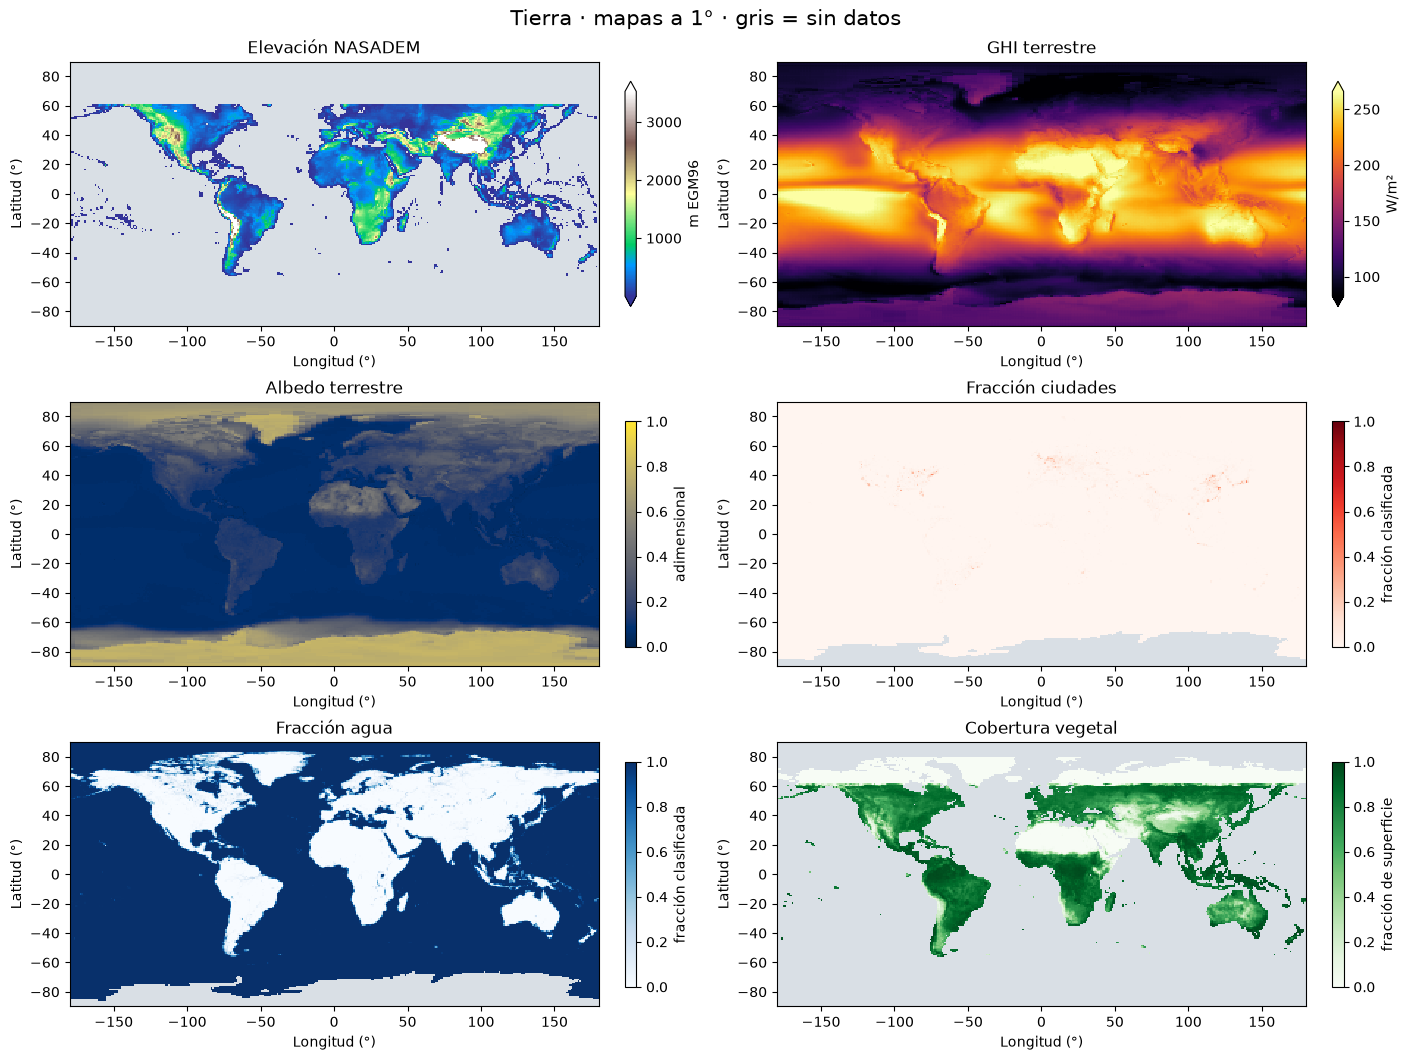

In [5]:
fig = proto.visualizar(datos, SALIDA)
plt.show()

### Próximo paso

La máscara categórica detallada permite excluir ciudades, agua y categorías vegetadas mediante sus bits 1, 2 y 4, comprobando antes `valor != 255` para separar desconocidos. El bit 8 identifica el suplemento oceánico Natural Earth; el código 10 sigue siendo agua. Esta clasificación sirve para exclusión y sigue siendo distinta de `datos["Cobertura vegetal"]`, la variable física continua 0–1 que ahora guarda la sexta banda del cubo. La lectura por ventanas y las definiciones se explican en [prototipo.md](./docu/prototipo.md).

**Un grado de la Tierra y un grado de Marte no representan la misma distancia.** El GHI marciano es un modelo simplificado a Ls = 18,9°, mientras el terrestre es una climatología anual. El albedo Lambert de Marte y el albedo superficial bajo todo cielo de POWER tienen definiciones diferentes. Deben armonizarse escalas, periodos y variables antes de calcular semejanzas físicas.

Los TIFF preparados permanecen en la carpeta temporal hasta comprobar su publicación en Hugging Face; después pueden eliminarse sin perder las fuentes remotas.